# A Gallery of Multiobjective Test Problems

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L12/L12_mop_gallery.ipynb)
### MECH 559 - Systems Optimization - L12
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Constrained MOP examples* and *Unconstrained MOP examples* slides. Twelve
classic biobjective test problems, each solved with DMulti-MADS in OMADS: six with constraints, six
without. They are the standard problems used to test multiobjective algorithms, chosen because their
fronts have every shape that makes the task hard: convex, non-convex, disconnected, clipped by
constraints, or hidden behind many local fronts.

The two summary figures at the end are the two slides. Running the whole notebook takes about 10
minutes, mostly for the 10- and 30-variable ZDT problems.

## Learning objectives

1. Recognize the main shapes of Pareto fronts and the difficulty each one poses.
2. See how constraints cut and reshape a front, and where the infeasible evaluations go.
3. Judge an approximate front against the true one when it is known, and explain the failures.

In [1]:
# %pip install OMADS==2612.1

In [2]:
import contextlib
import io
import os
import tempfile
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from OMADS import poll

os.environ.setdefault("PYTHONIOENCODING", "utf-8")    # OMADS prints Unicode progress bars
plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"dominated": "#B8BCC2", "infeasible": "#E9C46A", "front": "#1D5FA8", "true": "#111111"}
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print(f"OMADS {version('OMADS')}, NumPy {version('numpy')}")

OMADS 2612.1, NumPy 2.5.5


---
## 1. Solver and plotting helpers

The same `solve_omads` helper as in the running-example notebook (poll only, $w^+ = 3$, seed 0), and a
plot that separates the evaluations into three groups: dominated feasible, infeasible, and the
non-dominated feasible points, which form the approximate front.

In [3]:
def solve_omads(problem, baseline, lb, ub, budget=2000, seed=0, w_plus=3):
    """Run a biobjective OMADS study quietly. Returns (evaluations DataFrame, seconds)."""
    log = []

    def blackbox(x):
        f, c = problem(np.asarray(x, dtype=float))
        log.append([float(f[0]), float(f[1]), (max(c) <= 0) if len(c) else True])
        return [[float(v) for v in f], [float(v) for v in c] if len(c) else [0.0]]

    n = len(lb)
    param = {"baseline": list(baseline), "lb": list(lb), "ub": list(ub), "nobj": 2, "is_pareto": True,
             "var_names": [f"x{i + 1}" for i in range(n)], "fun_names": ["f1", "f2"], "w_plus": w_plus,
             "scaling": 10.0, "post_dir": tempfile.mkdtemp(), "name": "mo"}
    options = {"seed": seed, "budget": budget, "tol": 1e-9, "display": False, "save_results": False,
               "check_cache": True, "store_cache": True, "opportunistic": False}
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        poll.main({"evaluator": {"blackbox": blackbox}, "param": param, "options": options})
    return pd.DataFrame(log, columns=["f1", "f2", "feasible"]), time.perf_counter() - t0


def nondominated(F):
    F = np.asarray(F, dtype=float)
    mask = np.ones(len(F), dtype=bool)
    order = np.lexsort((F[:, 1], F[:, 0]))          # sweep in f1 order: O(n log n) for two objectives
    best_f2 = np.inf
    for i in order:
        if F[i, 1] < best_f2:
            best_f2 = F[i, 1]
        else:
            mask[i] = False
    return mask


def plot_problem(ax, name, evals, true_front=None, xlim=None, ylim=None):
    feas = evals[evals["feasible"]]
    nd = nondominated(feas[["f1", "f2"]].to_numpy())
    inf = evals[~evals["feasible"]]
    ax.scatter(feas["f1"][~nd], feas["f2"][~nd], s=4, color=COLORS["dominated"], alpha=0.6, label="dominated feasible")
    if len(inf):
        ax.scatter(inf["f1"], inf["f2"], s=4, color=COLORS["infeasible"], alpha=0.6, label="infeasible")
    if true_front is not None:
        ax.plot(*true_front, ".", ms=1.5, color=COLORS["true"], label="true Pareto front")
    ax.scatter(feas["f1"][nd], feas["f2"][nd], s=7, color=COLORS["front"], zorder=5, label="non-dominated feasible")
    ax.set(title=name, xlabel="$f_1$", ylabel="$f_2$", xlim=xlim, ylim=ylim)
    return int(nd.sum())

---
## 2. Constrained problems

| Problem | $n$ | Bounds | Objectives | Constraints ($\le 0$ form in the code) |
|---|---|---|---|---|
| Binh and Korn (BNH) | 2 | $[0,5]\times[0,3]$ | $4x_1^2 + 4x_2^2$, $(x_1-5)^2 + (x_2-5)^2$ | $(x_1-5)^2 + x_2^2 \le 25$, $(x_1-8)^2 + (x_2+3)^2 \ge 7.7$ |
| Chankong and Haimes | 2 | $[-20,20]^2$ | $2 + (x_1-2)^2 + (x_2-1)^2$, $9x_1 - (x_2-1)^2$ | $x_1^2 + x_2^2 \le 225$, $x_1 - 3x_2 + 10 \le 0$ |
| CONSTR | 2 | $[0.1,1]\times[0,5]$ | $x_1$, $(1 + x_2)/x_1$ | $x_2 + 9x_1 \ge 6$, $-x_2 + 9x_1 \ge 1$ |
| CTP1 | 2 | $[0,1]^2$ | $x_1$, $g\,e^{-x_1/g}$ with $g = 1 + x_2$ | $f_2 \ge 0.858\,e^{-0.541 f_1}$, $f_2 \ge 0.728\,e^{-0.295 f_1}$ |
| Osyczka and Kundu (OSY) | 6 | see code | $-[25(x_1-2)^2 + (x_2-2)^2 + (x_3-1)^2 + (x_4-4)^2 + (x_5-1)^2]$, $\sum x_i^2$ | the six constraints of the running example |
| Test function 4 | 2 | $[-7,4]^2$ | $x_1^2 - x_2$, $-0.5x_1 - x_2 - 1$ | three linear constraints |

The running example of the lecture is a variant of OSY.

In [4]:
def bnh(x):
    return ([4 * x[0] ** 2 + 4 * x[1] ** 2, (x[0] - 5) ** 2 + (x[1] - 5) ** 2],
            [(x[0] - 5) ** 2 + x[1] ** 2 - 25, 7.7 - (x[0] - 8) ** 2 - (x[1] + 3) ** 2])


def chankong_haimes(x):
    return ([2 + (x[0] - 2) ** 2 + (x[1] - 1) ** 2, 9 * x[0] - (x[1] - 1) ** 2],
            [x[0] ** 2 + x[1] ** 2 - 225, x[0] - 3 * x[1] + 10])


def constr(x):
    return [x[0], (1 + x[1]) / x[0]], [6 - x[1] - 9 * x[0], 1 + x[1] - 9 * x[0]]


def ctp1(x):
    g = 1 + x[1]
    f1, f2 = x[0], g * np.exp(-x[0] / g)
    return [f1, f2], [0.858 * np.exp(-0.541 * f1) - f2, 0.728 * np.exp(-0.295 * f1) - f2]


def osy(x):
    f1 = -(25 * (x[0] - 2) ** 2 + (x[1] - 2) ** 2 + (x[2] - 1) ** 2 + (x[3] - 4) ** 2 + (x[4] - 1) ** 2)
    c = [2 - x[0] - x[1], x[0] + x[1] - 6, x[1] - x[0] - 2, x[0] - 3 * x[1] - 2,
         (x[2] - 3) ** 2 + x[3] - 4, 4 - (x[4] - 3) ** 2 - x[5]]
    return [f1, np.sum(x ** 2)], c


def test_function_4(x):
    return ([x[0] ** 2 - x[1], -0.5 * x[0] - x[1] - 1],
            [x[0] / 6 + x[1] - 6.5, 0.5 * x[0] + x[1] - 7.5, 5 * x[0] + x[1] - 30])


# name: (function, lower bounds, upper bounds, baseline, budget, axis limits)
CONSTRAINED = {
    "2D Binh and Korn": (bnh, [0, 0], [5, 3], [2.5, 1.5], 2000, ((0, 140), (0, 50))),
    "2D Chankong and Haimes": (chankong_haimes, [-20, -20], [20, 20], [-5, 5], 2000, ((0, 250), (-250, 0))),
    "2D CONSTR": (constr, [0.1, 0], [1, 5], [0.8, 1.0], 2000, ((0.3, 1), (1, 9))),
    "2D CTP1": (ctp1, [0, 0], [1, 1], [0.5, 0.5], 2000, ((0, 1), (0.5, 1.1))),
    "6D Osyczka and Kundu": (osy, [0, 0, 1, 0, 1, 0], [10, 10, 5, 6, 5, 10], [2, 2, 2, 2, 2, 5], 5000,
                             ((-300, 0), (0, 80))),
    "2D Test function 4": (test_function_4, [-7, -7], [4, 4], [0, 0], 2000, ((-4, 12), (-7, -5))),
}
for name, (fun, lb, ub, x0, *_) in CONSTRAINED.items():
    print(f"{name:24s} baseline feasible: {max(fun(np.array(x0, dtype=float))[1]) <= 0}")

2D Binh and Korn         baseline feasible: True
2D Chankong and Haimes   baseline feasible: True
2D CONSTR                baseline feasible: True
2D CTP1                  baseline feasible: True
6D Osyczka and Kundu     baseline feasible: True
2D Test function 4       baseline feasible: True


In [5]:
results_c, rows = {}, []
for name, (fun, lb, ub, x0, budget, lims) in CONSTRAINED.items():
    evals, seconds = solve_omads(fun, x0, lb, ub, budget=budget)
    results_c[name] = evals
    rows.append(dict(problem=name, budget=budget, seconds=seconds, feasible_share=evals["feasible"].mean(),
                     front_points=int(nondominated(evals.loc[evals["feasible"], ["f1", "f2"]].to_numpy()).sum())))
pd.DataFrame(rows).set_index("problem")

,budget,seconds,feasible_share,front_points
problem,,,,
2D Binh and Korn,2000,48.03,0.978,998
2D Chankong and Haimes,2000,31.16,0.8005,632
2D CONSTR,2000,24.84,0.619,306
2D CTP1,2000,22.33,0.6935,404
6D Osyczka and Kundu,5000,39.39,0.2892,144
2D Test function 4,2000,26.34,1,468


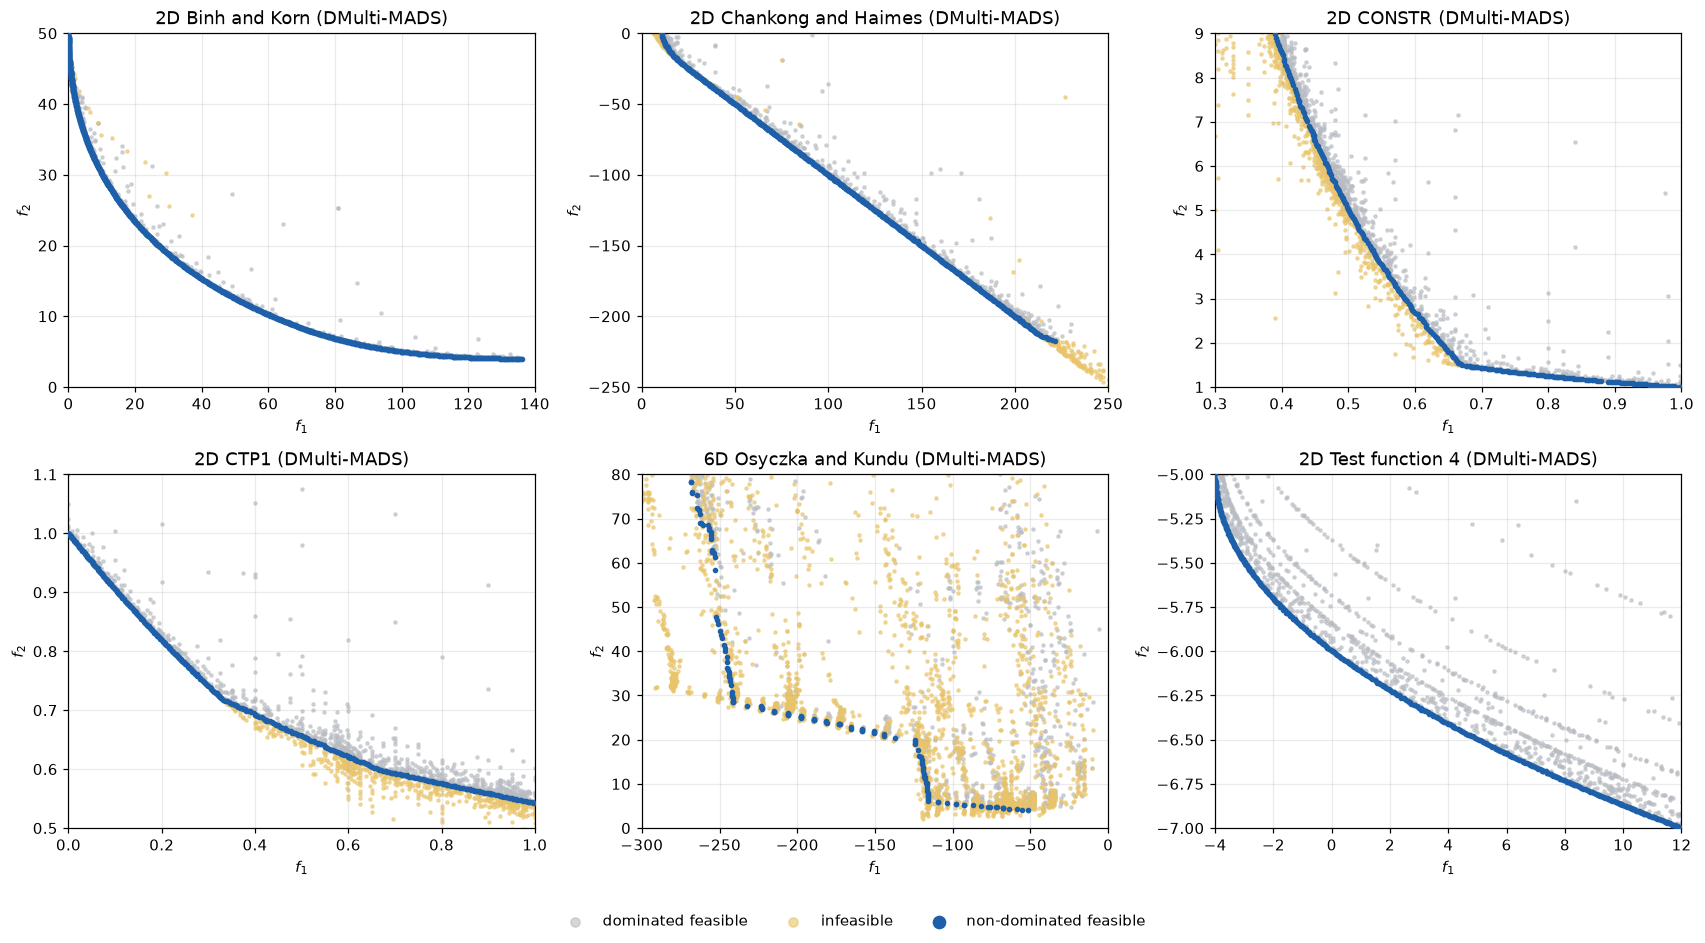

In [6]:
def gallery(results, problems, true_fronts=None, ncols=3):
    true_fronts = true_fronts or {}
    nrows = int(np.ceil(len(problems) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.3 * nrows))
    for ax, (name, spec) in zip(axes.flat, problems.items()):
        xlim, ylim = spec[-1]
        plot_problem(ax, f"{name} (DMulti-MADS)", results[name], true_fronts.get(name), xlim, ylim)
    handles, labels = {}, {}
    for ax in axes.flat:
        for h, lab in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(lab, h)
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=4, markerscale=3, frameon=False)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    return fig


fig_c = gallery(results_c, CONSTRAINED)
plt.show()

What to notice, problem by problem:

- **BNH**: a smooth convex front; almost every evaluation is feasible, and the constraints only clip
  the far end of the front. The easy case.
- **Chankong and Haimes**: the front is almost a straight line, bounded at both ends by the constraints.
- **CONSTR**: the left part of the front ($f_1 < 0.67$) lies **on** the constraint $x_2 + 9x_1 \ge 6$. The
  infeasible evaluations (yellow) crowd just below it: the front is a constraint boundary, and half of
  every poll around it is lost to the extreme barrier.
- **CTP1**: the unconstrained front is a single curve, but the two constraints replace part of it with
  the constraint curves; the true front is made of pieces of different curves.
- **OSY**: six variables and six constraints; the front is made of **several segments**, each lying on a
  different set of active constraints. This is the hardest one here: most of the evaluations are
  infeasible, and some segments are only sparsely covered.
- **Test function 4**: a smooth front, and every evaluation was feasible: the three linear constraints
  bound the box far from the front, so they never matter. A constrained problem is not always hard. The
  dominated points line up in bands, the traces of the poll moving along the front.

---
## 3. Unconstrained problems

| Problem | $n$ | Bounds | Front |
|---|---|---|---|
| Fonseca and Fleming | 2 | $[-4,4]^2$ | non-convex |
| Kursawe | 3 | $[-5,5]^3$ | disconnected, non-convex pieces |
| ZDT1 | 30 | $[0,1]^{30}$ | convex, $f_2 = 1 - \sqrt{f_1}$ |
| ZDT3 | 10 | $[0,1]^{10}$ | disconnected (5 pieces) |
| ZDT4 | 10 | $x_1 \in [0,1]$, $[-5,5]^9$ | convex, but $21^9$ local fronts |
| ZDT6 | 10 | $[0,1]^{10}$ | non-convex, points crowded at one end |

The ZDT problems (Zitzler, Deb and Thiele, 2000) share one structure: $f_1$ depends on $x_1$ only, a
function $g$ of the other variables equals 1 on the Pareto set, and $f_2 = g\,h(f_1, g)$. Their true
fronts are known exactly, so we draw them.

In [7]:
def fonseca_fleming(x):
    a = 1 / np.sqrt(len(x))
    return [1 - np.exp(-np.sum((x - a) ** 2)), 1 - np.exp(-np.sum((x + a) ** 2))], []


def kursawe(x):
    f1 = np.sum(-10 * np.exp(-0.2 * np.sqrt(x[:-1] ** 2 + x[1:] ** 2)))
    f2 = np.sum(np.abs(x) ** 0.8 + 5 * np.sin(x ** 3))
    return [f1, f2], []


def zdt1(x):
    g = 1 + 9 * np.mean(x[1:])
    return [x[0], g * (1 - np.sqrt(x[0] / g))], []


def zdt3(x):
    g = 1 + 9 * np.mean(x[1:])
    return [x[0], g * (1 - np.sqrt(x[0] / g) - x[0] / g * np.sin(10 * np.pi * x[0]))], []


def zdt4(x):
    g = 1 + 10 * (len(x) - 1) + np.sum(x[1:] ** 2 - 10 * np.cos(4 * np.pi * x[1:]))
    return [x[0], g * (1 - np.sqrt(x[0] / g))], []


def zdt6(x):
    f1 = 1 - np.exp(-4 * x[0]) * np.sin(6 * np.pi * x[0]) ** 6
    g = 1 + 9 * np.mean(x[1:]) ** 0.25
    return [f1, g * (1 - (f1 / g) ** 2)], []


UNCONSTRAINED = {
    "2D Fonseca Fleming": (fonseca_fleming, [-4] * 2, [4] * 2, [0.0] * 2, 2000, ((0, 1), (0, 1))),
    "3D Kursawe": (kursawe, [-5] * 3, [5] * 3, [0.0] * 3, 3000, ((-20, -14), (-12, 2))),
    "30D ZDT1": (zdt1, [0] * 30, [1] * 30, [0.5] * 30, 8000, ((0, 1), (0, 1))),
    "10D ZDT3": (zdt3, [0] * 10, [1] * 10, [0.5] * 10, 6000, ((0, 0.9), (-0.8, 1))),
    "10D ZDT4": (zdt4, [0] + [-5] * 9, [1] + [5] * 9, [0.5] + [1.0] * 9, 6000, ((0, 1), (0, 1.2))),
    "10D ZDT6": (zdt6, [0] * 10, [1] * 10, [0.5] * 10, 6000, ((0, 1), (0, 1.2))),
}

f1 = np.linspace(0, 1, 2000)
s = np.linspace(-1, 1, 400) / np.sqrt(2)
ff_front = np.array([fonseca_fleming(np.array([v, v]))[0] for v in s]).T
zdt3_all = np.array([f1, 1 - np.sqrt(f1) - f1 * np.sin(10 * np.pi * f1)])
f6 = np.linspace(0.2808, 1, 2000)
TRUE_FRONTS = {"2D Fonseca Fleming": ff_front,
               "30D ZDT1": np.array([f1, 1 - np.sqrt(f1)]),
               "10D ZDT3": zdt3_all[:, nondominated(zdt3_all.T)],
               "10D ZDT4": np.array([f1, 1 - np.sqrt(f1)]),
               "10D ZDT6": np.array([f6, 1 - f6 ** 2])}

In [8]:
results_u, rows = {}, []
for name, (fun, lb, ub, x0, budget, lims) in UNCONSTRAINED.items():
    evals, seconds = solve_omads(fun, x0, lb, ub, budget=budget)
    results_u[name] = evals
    F = evals[["f1", "f2"]].to_numpy()
    nd = F[nondominated(F)]
    row = dict(problem=name, budget=budget, seconds=seconds, front_points=len(nd))
    if name in TRUE_FRONTS:                       # distance from each front point to the true front
        T = TRUE_FRONTS[name].T
        d = np.sqrt(((nd[:, None, :] - T[None, :, :]) ** 2).sum(axis=2)).min(axis=1)
        row.update(mean_distance_to_true_front=d.mean(), max_distance=d.max())
    rows.append(row)
pd.DataFrame(rows).set_index("problem")

,budget,seconds,front_points,mean_distance_to_true_front,max_distance
problem,,,,,
2D Fonseca Fleming,2000,15.7,282,0.001098,0.003374
3D Kursawe,3000,23.6,448,NaN,NaN
30D ZDT1,8000,228.7,352,0.0002432,0.001686
10D ZDT3,6000,45.06,418,0.00132,0.007844
10D ZDT4,6000,32.06,108,0.3272,11
10D ZDT6,6000,43.57,474,0.0001646,0.000401


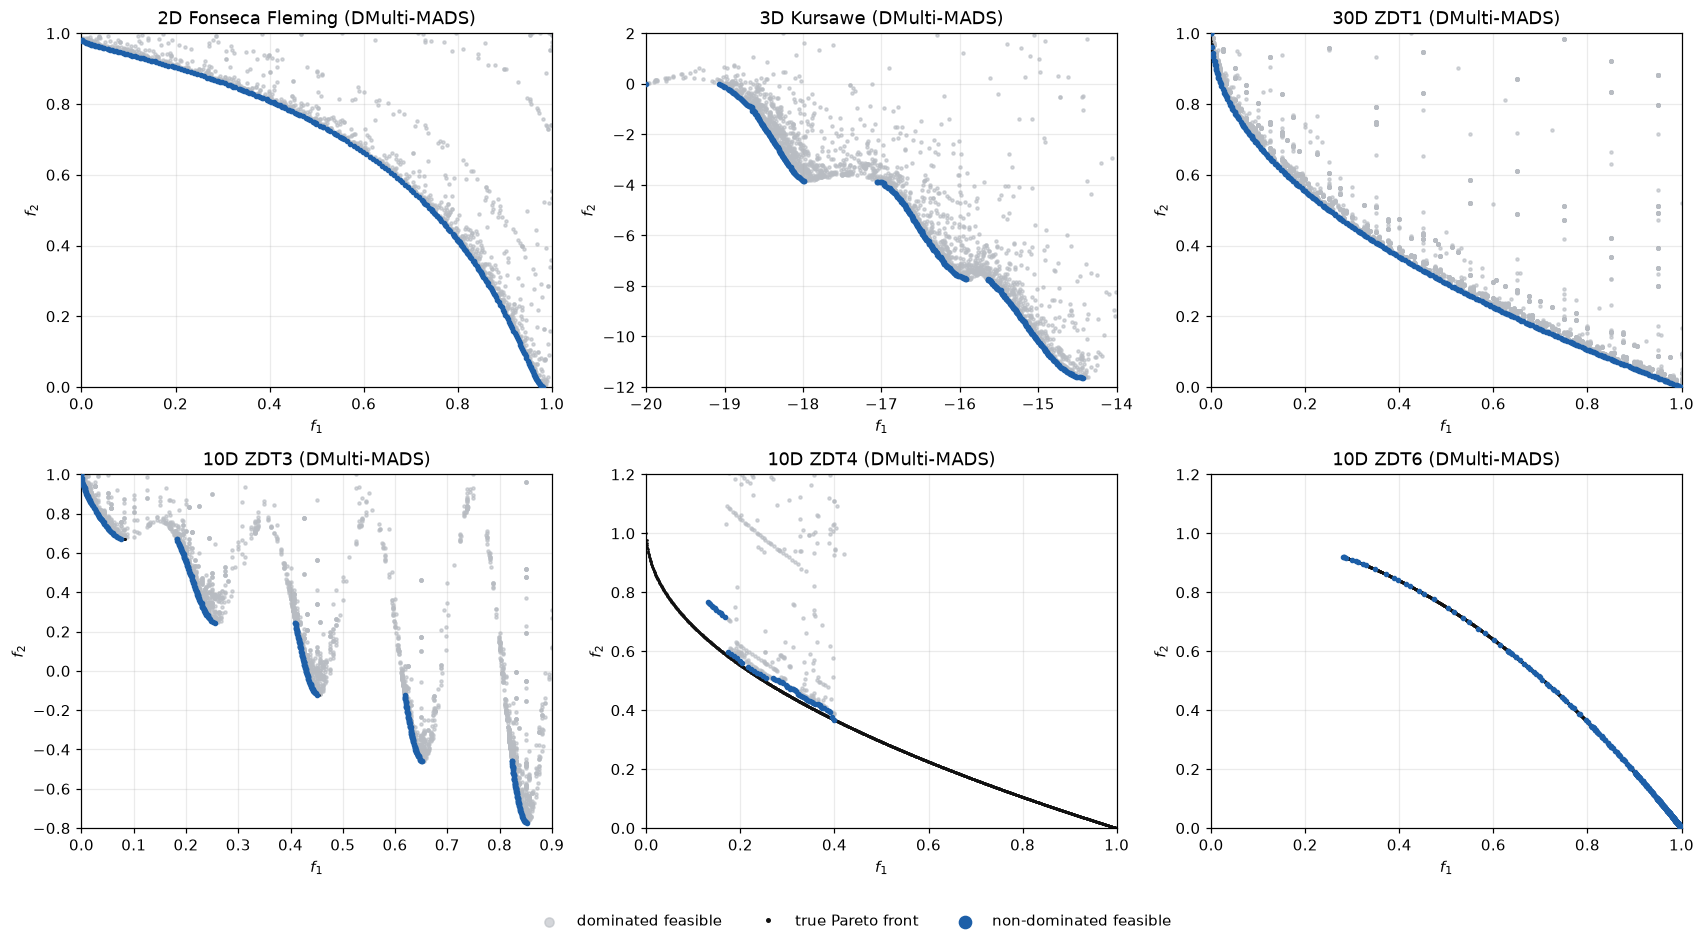

In [9]:
fig_u = gallery(results_u, UNCONSTRAINED, TRUE_FRONTS)
plt.show()

What to notice:

- **Fonseca and Fleming**: the non-convex front of the earlier notebooks, traced completely.
- **Kursawe**: the front breaks into separate pieces, and the dominated evaluations show a very irregular
  $F(\Omega)$. A list of non-dominated points handles disconnected fronts naturally: each piece holds its
  own points with their own frame sizes.
- **ZDT1** (30 variables): the front is easy in shape but costly in dimension. Each poll costs $2n = 60$
  evaluations, so 8000 evaluations are only about 130 iterations, and the run is the slowest of the
  gallery. The list still reaches the true front over its whole length.
- **ZDT3**: the five disconnected pieces are all found, and each one is traced.
- **ZDT4**: the convex front is hidden behind many **local** fronts ($g$ has cosine bumps in 9 variables).
  Local polling gets stuck: the list only covers $f_1 \in [0.13, 0.4]$, and parts of it sit on local
  fronts above the true curve (see the distances in the table). This is the one failure of the gallery.
- **ZDT6**: the points of $F(\Omega)$ crowd near $f_1 = 1$ and the front is non-convex, yet it is traced
  completely, down to its true left end at $f_1 \approx 0.28$.

> **Checkpoint.** Which two features of a problem made DMulti-MADS struggle in this gallery? *Answer:*
> many local fronts (ZDT4: a local method converges to the first front it finds), and, for the cost, a
> large number of variables (ZDT1: each poll costs $2n$ evaluations). The shape of the front
> (non-convex, disconnected) was not a problem, which is the main advantage of a dominance-based method
> over a weighted sum.

---
## Exercises

1. **Budget for ZDT1.** Double the budget of ZDT1. How do the mean distance to the true front and the
   number of front points change? Is the budget per variable the right way to think about the cost?
2. **Escaping local fronts.** Run ZDT4 with three seeds. Do the fronts differ? Try starting from a point
   with $x_2 = \dots = x_{10} = 0$ (on the Pareto set): what changes, and why is it cheating?
3. **Scaling.** In CONSTR, $f_2$ is ten times larger than $f_1$. Does that matter for DMulti-MADS? (Hint:
   which steps of the algorithm compare values of different objectives?)
4. **Hypervolume ranking.** Choose a reference point for each problem and compute the hypervolume of the
   front with budgets of 500, 1000 and 2000. Which problems have converged at 1000?

---
## Takeaways

1. Test problems are designed to isolate one difficulty each: shape (non-convex, disconnected),
   constraints, number of variables, or local fronts.
2. Constraints often **form** part of the front; the evaluations then concentrate on the constraint
   boundary, and many of them are infeasible.
3. Dominance-based methods are insensitive to the shape of the front. Their weaknesses are the cost of
   polling in high dimension and, as for any local method, local fronts.